# HackINE — 02 · Análisis exploratorio histórico

EDA ponderado de participación por elección, por grupos de edad y contraste descriptivo por sexo/tipo de sección. No se realiza inferencia individual.

Fuente: ZIPs CCPC del INE conservados en `datos/raw/`. Se trabaja sobre sus agregaciones verificables en `datos/processed/`. Los resultados representan **grupos estadísticos, no personas individuales**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().resolve()
if not (ROOT/'datos').exists():
    ROOT = ROOT.parent.parent
assert (ROOT/'datos'/'processed').exists(), f'Abra el proyecto raíz, no otro directorio: {ROOT}'
plt.rcParams.update({'figure.figsize':(9,4.3),'figure.dpi':110})


## Evolución de participación nacional (ponderada por observados)

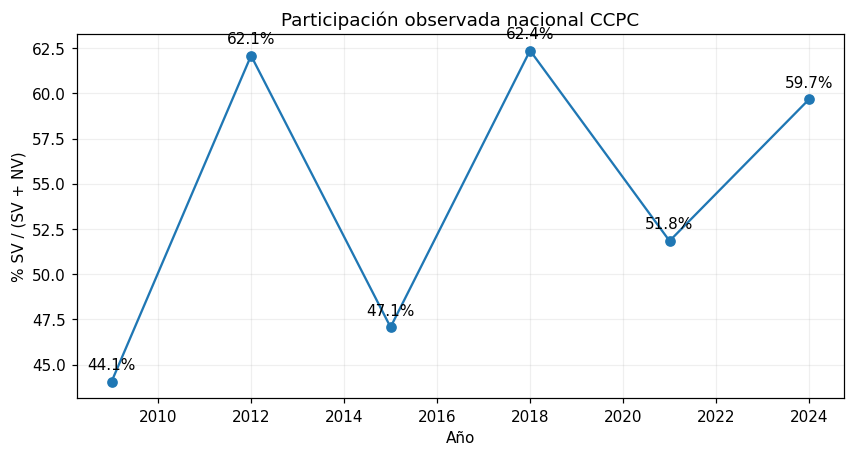

,anio,tipo,participacion_pct,ns_pct
0,2009,Intermedia,44.06,2.41
1,2012,Presidencial,62.08,0.22
2,2015,Intermedia,47.07,6.13
3,2018,Presidencial,62.37,6.83
4,2021,Intermedia,51.84,4.32
5,2024,Presidencial,59.67,6.43


In [2]:
n=pd.read_csv(ROOT/'analisis/reportes/resumen_nacional.csv')
plt.plot(n.anio,n.participacion_pct,marker='o')
for _,r in n.iterrows():plt.annotate(f'{r.participacion_pct:.1f}%',(r.anio,r.participacion_pct),xytext=(0,8),textcoords='offset points',ha='center')
plt.title('Participación observada nacional CCPC');plt.xlabel('Año');plt.ylabel('% SV / (SV + NV)');plt.grid(alpha=.2);plt.show()
display(n[['anio','tipo','participacion_pct','ns_pct']].round(2))

## Trayectorias transversales por edades (no son cohortes individuales)

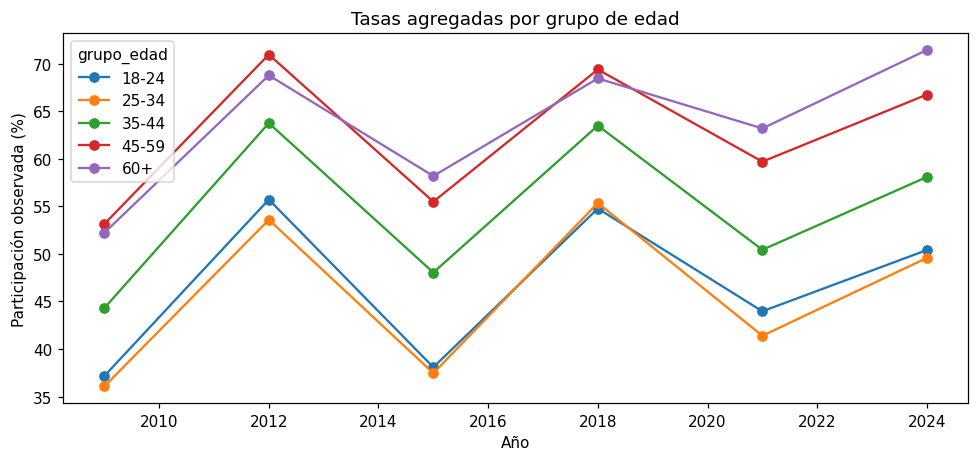

grupo_edad,18-24,25-34,35-44,45-59,60+
anio,,,,,
2009,37.16,36.07,44.30,53.14,52.21
2012,55.70,53.58,63.74,70.95,68.76
2015,38.08,37.46,48.04,55.48,58.18
2018,54.76,55.34,63.48,69.38,68.44
2021,43.96,41.39,50.42,59.69,63.18
2024,50.40,49.57,58.08,66.74,71.42


In [3]:
age=pd.read_csv(ROOT/'analisis/reportes/participacion_por_edad_y_anio.csv')
a=age.pivot(index='anio',columns='grupo_edad',values='participacion_pct')
ax=a[['18-24','25-34','35-44','45-59','60+']].plot(marker='o')
ax.set(title='Tasas agregadas por grupo de edad',ylabel='Participación observada (%)',xlabel='Año');plt.tight_layout();plt.show()
display(a.round(2))

## Sexo: comparación descriptiva agregada (2024 incluye la categoría 2)

In [4]:
s=pd.read_csv(ROOT/'analisis/reportes/participacion_por_sexo_y_anio.csv')
display(s[['anio','SEXO','LN','participacion_pct']].round(2))
print('No inferir comportamiento de personas; evitar divulgar granularidad de categorías con base pequeña.')

,anio,SEXO,LN,participacion_pct
0,2009,0,37353906,40.53
1,2009,1,40127925,47.35
2,2012,0,36821304,57.78
3,2012,1,39669658,66.08
4,2015,0,40219786,42.95
5,2015,1,43343676,50.89
6,2018,0,42913845,58.14
7,2018,1,46210152,66.28
8,2021,0,45067547,47.76
9,2021,1,48464586,55.62


No inferir comportamiento de personas; evitar divulgar granularidad de categorías con base pequeña.


## Secciones U/M/R (composición, no causalidad)

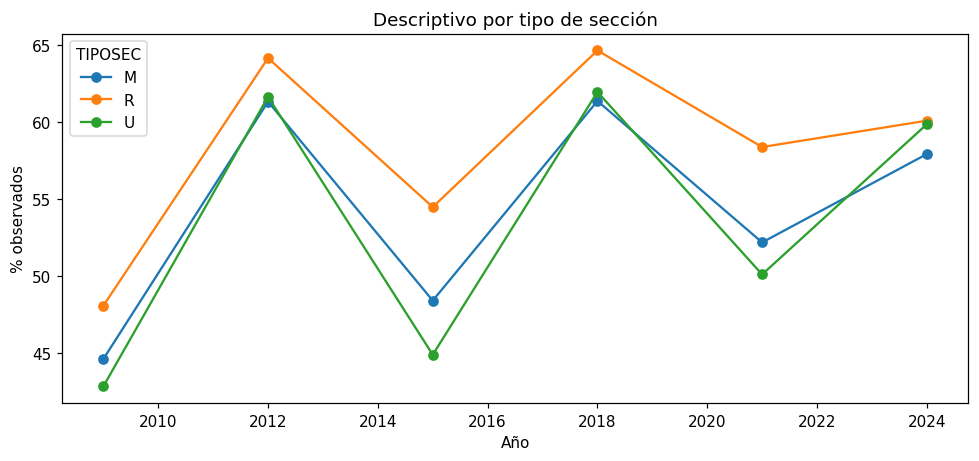

In [5]:
t=pd.read_csv(ROOT/'analisis/reportes/participacion_por_tipo_seccion_y_anio.csv')
ax=t.pivot(index='anio',columns='TIPOSEC',values='participacion_pct').plot(marker='o')
ax.set(title='Descriptivo por tipo de sección',ylabel='% observados',xlabel='Año');plt.tight_layout();plt.show()